# Module 3: Machine Learning for Classification

## Beginner's Study Guide + Homework 3 Working Solutions

*Part A teaches the churn-prediction project step by step (every unit of the module). Part B solves Homework 3 (lead scoring) with complete, tested code and the answers.*

## How to use this document

- Read Part A in order; each step builds on the last.
- Every step: **Goal → Idea → Code → Remember → Common confusion**.
- Part B reuses almost everything from Part A, so do Part A first.
- All code was run to produce the numbers shown. Where my numbers differ slightly from the lessons, I say so (different library versions cause small differences).

### Table of contents

**Part A: Study guide**
- [Part 0: Glossary and prerequisites](#part-0-glossary-and-prerequisites)
- [Step 1: The churn problem and binary classification](#step-1-the-churn-problem-and-binary-classification)
- [Step 2: Data preparation](#step-2-data-preparation)
- [Step 3: Validation framework with Scikit-Learn](#step-3-validation-framework-with-scikit-learn)
- [Step 4: EDA](#step-4-eda)
- [Step 5: Feature importance, part 1: churn rate and risk ratio](#step-5-feature-importance-part-1-churn-rate-and-risk-ratio)
- [Step 6: Feature importance, part 2: mutual information](#step-6-feature-importance-part-2-mutual-information)
- [Step 7: Feature importance, part 3: correlation](#step-7-feature-importance-part-3-correlation)
- [Step 8: One-hot encoding with DictVectorizer](#step-8-one-hot-encoding-with-dictvectorizer)
- [Step 9: Logistic regression: the idea](#step-9-logistic-regression-the-idea)
- [Step 10: Training logistic regression with Scikit-Learn](#step-10-training-logistic-regression-with-scikit-learn)
- [Step 11: Interpreting the model](#step-11-interpreting-the-model)
- [Step 12: Using the model](#step-12-using-the-model)
- [Step 13: The whole project in one place](#step-13-the-whole-project-in-one-place)
- [Cheat sheets](#cheat-sheets)
- [Common confusions (FAQ)](#common-confusions-faq)
- [Self-test questions](#self-test-questions)

**Part B: Homework 3**
- [Setup and data preparation](#homework-setup-and-data-preparation)
- [Question 1 to Question 6](#question-1)
- [Complete solution script](#complete-homework-solution-script)
- [Answer summary](#answer-summary)

# PART A: STUDY GUIDE

## Part 0: Glossary and prerequisites

### Words you will see everywhere

| Term | Plain-English meaning | Example here |
|---|---|---|
| **Classification** | ML problem where we predict a **category**. | Will the customer leave: yes or no? |
| **Binary classification** | Exactly two categories, coded **0** and **1**. | 1 = churned, 0 = stayed. |
| **Positive class** | The category coded 1 (the one we look for). | Churned. |
| **Churn** | A customer stops using a service. | Cancelling the phone contract. |
| **Churn rate** | Share of customers who churned. | 27%. |
| **Feature** | One input column. | Contract type, tenure. |
| **Target** (`y`) | What we predict. | `churn` (0/1). |
| **Categorical variable** | Values are labels. | `contract = two_year`. |
| **Numerical variable** | Values are quantities. | `tenure = 24` months. |
| **Probability** | A number between 0 and 1: "how likely". | 0.8 = 80% likely. |
| **Score** | The raw number before turning it into a probability. | -3.47. |
| **Threshold** | Cut-off for turning a probability into a yes/no decision. | 0.5. |
| **Accuracy** | Share of predictions that are correct. | 80%. |
| **One-hot encoding** | Turning a category into 0/1 columns. | `contract=two_year`. |
| **Sigmoid** | A function that squashes any number into 0 to 1. | See Step 9. |
| **Weights / bias** | Numbers the model learns. | `coef_`, `intercept_`. |
| **Feature importance** | How much a feature helps predict the target. | Mutual information. |
| **Reproducibility** | Getting the same results each run. | `random_state=1`. |

### Tools used

### 📓 Notebook notes

- **Run the cells from top to bottom.** Later cells depend on earlier ones.
- Cells marked *expected to fail* fail on purpose (to show a problem).
- **Part A** downloads the Telco churn data. **Part B** switches to a different dataset (lead scoring) and reuses the names `df`, `categorical`, `numerical`, `df_train`, ... so it starts fresh. If you restart the kernel, run from the top again.
- Scikit-Learn may print a `ConvergenceWarning` for `lbfgs` on the churn data. It's harmless here (see Step 10).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

**Scikit-Learn** (`sklearn`) is a library with ready-made ML tools. In Module 2 we wrote linear regression ourselves; from now on we let the library do the heavy lifting.

> ⚠️ **A pandas-version gotcha you will meet in this module.** The lessons find text columns with `df.dtypes == 'object'`. In **pandas 3.x** text columns have the type `str`, not `object`, so that check silently returns an **empty list**. A version-proof way to find text columns:
> ```python
> text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
> ```
> Use this if the lesson code seems to "do nothing".

## Step 1: The churn problem and binary classification

**Goal:** understand what we are predicting and why.

### The business problem

A telecom company loses customers every month (they "churn"). Losing customers is expensive, so the company wants to spot likely leavers **before** they leave and offer them, for example, a discount email.

For every customer the model produces a **score between 0 and 1**: the probability that this customer will churn. The company then contacts customers with high scores.

### Binary classification

We want a model `g` such that, for the i-th customer:

```
g(xi) ≈ yi
```

- `xi` = everything we know about customer *i* (the feature vector)
- `yi` = what happened: **1** (churned) or **0** (stayed)
- `g(xi)` = the model's output: a probability between 0 and 1

We train `g` on **historical** customers (we already know what happened to them), then apply it to **current** customers.

### The dataset

Kaggle's *Telco Customer Churn*: 7,043 customers, 21 columns:

| Group | Columns |
|---|---|
| ID | `customerid` |
| Demographics | `gender`, `seniorcitizen`, `partner`, `dependents` |
| Services | `phoneservice`, `multiplelines`, `internetservice`, `onlinesecurity`, `onlinebackup`, `deviceprotection`, `techsupport`, `streamingtv`, `streamingmovies` |
| Account | `contract`, `paperlessbilling`, `paymentmethod` |
| Charges | `monthlycharges`, `totalcharges` |
| Tenure | `tenure` (months with the company) |
| **Target** | `churn` |

### Remember

- Classification predicts a category; our model outputs a **probability** of the positive class.
- 1 = churned (positive), 0 = stayed (negative).

## Step 2: Data preparation

**Goal:** load the data, make names and values consistent, fix one broken column, and turn the target into 0/1.

### 2.1 Download and load

In [9]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
!curl -sL $data -o data-week-3.csv

- In a notebook, a line starting with `!` runs a **terminal command**.
- `$data` inserts the Python variable `data` into that command.
- `-O data-week-3.csv` names the downloaded file.

In [10]:
df = pd.read_csv('data-week-3.csv')
df.head()
df.head().T      # .T = transpose: rows <-> columns; handy for 21 columns

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


### 2.2 Make names and values uniform

Same as Module 2: lowercase everything, spaces to underscores.

In [11]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

# text columns = all non-numeric columns (works on old AND new pandas; see the pandas-3 note in Part 0)
categorical_columns = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

### 2.3 Fix `totalcharges`

`df.dtypes` shows `totalcharges` is text, although it holds numbers. Why? Some entries are blank (a space in the original file; after our cleaning it became `"_"`). `pd.to_numeric` can't parse `"_"`:

In [12]:
# EXPECTED TO FAIL: "_" cannot be turned into a number
try:
    pd.to_numeric(df.totalcharges)
except ValueError as e:
    print("ValueError:", e)

ValueError: Unable to parse string "_" at position 488


`errors='coerce'` means "if you can't convert something, turn it into NaN instead of crashing":

In [13]:
tc = pd.to_numeric(df.totalcharges, errors='coerce')
tc.isnull().sum()                   # 11 rows

np.int64(11)

These 11 customers just joined and haven't been billed, so filling with **0** is reasonable:

In [14]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

### 2.4 Encode the target

`churn` holds `'yes'`/`'no'`. Models need numbers:

In [15]:
df.churn = (df.churn == 'yes').astype(int)

How it works: `df.churn == 'yes'` gives True/False; `.astype(int)` turns True → 1, False → 0.

Other columns such as `seniorcitizen` are already 0/1. We keep them and later treat them as categorical.

### Remember

- `!wget`, `pd.read_csv`, `df.head().T`
- `pd.to_numeric(..., errors='coerce')` turns bad values into NaN; then `fillna`.
- `(df.col == 'yes').astype(int)` converts yes/no to 1/0.

## Step 3: Validation framework with Scikit-Learn

**Goal:** split into train / validation / test (60/20/20) and set the target aside.

Why we split is the same as in Module 2: judge the model on data it never trained on. (Training on the "exam questions" would give a flattering, meaningless score.)

### 3.1 The two-step split

`train_test_split` splits into **two** parts only, so we call it twice:

In [16]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

**Why `0.25` the second time?** After removing the test set, 80% of the data remains. We want validation to be 20% of the **original** data. 20% of 80% is not 20%; it's **25%** (0.25 × 0.8 = 0.2). So:

| Set | Share of original | Rows |
|---|---|---|
| train | 60% | 4,225 |
| validation | 20% | 1,409 |
| test | 20% | 1,409 |

`random_state=1` fixes the random shuffle, so everyone gets the same split.

In [17]:
len(df_train), len(df_val), len(df_test)     # (4225, 1409, 1409)

(4225, 1409, 1409)

### 3.2 Reset the index and set the target aside

In [18]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

- `reset_index(drop=True)`: renumber rows 0, 1, 2, ... (the shuffle scrambled them) and discard the old numbers.
- `.values`: plain NumPy array.
- `del`: **remove the target from the features** so it can't accidentally leak into the model.
- We **keep `churn` inside `df_full_train`**, because the next steps (EDA and feature importance) need it.

### Remember

- Two calls to `train_test_split`; second one uses `test_size=0.25`.
- Seed (`random_state`) = reproducible.
- Delete the target from the feature tables.

## Step 4: EDA

**Goal:** explore the training data before modelling. We use `df_full_train` (train + validation), because we'll also measure feature importance on it.

In [19]:
df_full_train = df_full_train.reset_index(drop=True)

### 4.1 Missing values

In [20]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

All zeros: nothing is missing (we already handled `totalcharges`).

### 4.2 The target: churn rate

In [21]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

```
0    0.730032
1    0.269968
```

- `normalize=True` gives shares instead of counts.
- About **73% stayed, 27% churned**. The 27% is the **churn rate**.

Shortcut: the **mean of a 0/1 column is the share of ones**:

In [22]:
df_full_train.churn.mean()      # 0.26996805...

np.float64(0.26996805111821087)

This trick works for any binary column, and we'll use it constantly.

### 4.3 Numerical vs categorical columns

In [23]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice',
    'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup',
    'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies',
    'contract', 'paperlessbilling', 'paymentmethod',
]

- `seniorcitizen` is stored as 0/1, but it is really a **category** (senior / not senior).
- `customerid` is an identifier: useless as a feature, so it's in neither list.
- `churn` is the target.

In [24]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

Most have 2 or 3 values; `paymentmethod` has 4. This matters later: the number of values decides how many columns one-hot encoding creates.

### Remember

- `value_counts(normalize=True)` and `.mean()` both give the churn rate.
- Always keep two lists: `numerical` and `categorical`.

## Step 5: Feature importance, part 1: churn rate and risk ratio

**Goal:** find which features actually affect churn. Feature importance is part of EDA.

### 5.1 Compare a group with everyone

Reference point:

In [25]:
global_churn = df_full_train.churn.mean()      # 0.2700

Gender:

In [26]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()   # 0.2768
churn_male   = df_full_train[df_full_train.gender == 'male'].churn.mean()     # 0.2632

Breaking down that line: `df[df.gender == 'female']` keeps the female rows; `.churn.mean()` is the churn rate among them.

Both are very close to 0.27, so **gender tells us almost nothing**.

Now `partner`:

In [27]:
churn_partner    = df_full_train[df_full_train.partner == 'yes'].churn.mean()   # 0.2050
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()    # 0.3298

Very different from 0.27: **single customers churn much more**.

### 5.2 Two ways to compare

| Measure | Formula | Meaning |
|---|---|---|
| **Difference** | `group rate − global rate` (in the loop below) | Absolute gap. Positive = group churns **more**. |
| **Risk ratio** | `group rate / global rate` | Relative gap. |

> ⚠️ **Sign confusion alert.** In the first part of the lesson the difference was computed as *global − group* (positive = group churns **less**). In the `groupby` loop it is *group − global* (positive = group churns **more**). Same idea, opposite sign. Whenever you see a "diff", check which way it was subtracted. The **risk ratio** has no such problem.

**Reading the risk ratio:**

- risk = 1 → same as average
- risk > 1 → more likely to churn
- risk < 1 → less likely

`no partner`: 0.3298 / 0.27 = **1.22**: churn 22% more often than average.
`partner`: **0.76**: churn about 24% less often.

### 5.3 Do it for every variable with `groupby`

The SQL equivalent:

```sql
SELECT gender, AVG(churn), AVG(churn) - global_churn AS diff, AVG(churn) / global_churn AS risk
FROM data GROUP BY gender;
```

In pandas:

In [28]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980



seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208



partner


...

,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560



paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


Line by line:

- `groupby(c)`: split rows into groups by the values of column `c`.
- `.churn.agg(['mean', 'count'])`: for each group, compute the churn rate and the group size.
- `diff`, `risk`: the two comparison columns.
- `display(...)`: shows a table inside a loop (inside loops, tables are not shown automatically).

Key results (risk ratios):

| Variable | Group | Churn rate | Risk |
|---|---|---:|---:|
| contract | month-to-month | 0.432 | **1.60** |
| contract | one_year | 0.121 | 0.45 |
| contract | two_year | 0.028 | **0.10** |
| internetservice | fiber_optic | 0.425 | 1.57 |
| internetservice | dsl | 0.192 | 0.71 |
| paymentmethod | electronic_check | 0.456 | **1.69** |
| paymentmethod | credit_card_(automatic) | 0.164 | 0.61 |

So contract type, internet service and payment method look important; gender and phone service don't. What these tables **can't** do is rank whole variables against each other. That is what the next step is for.

### Remember

- Risk > 1: riskier; < 1: safer.
- `groupby(col).churn.agg(['mean', 'count'])` is the workhorse.

## Step 6: Feature importance, part 2: mutual information

**Goal:** one number per categorical variable, so we can rank them.

### 6.1 The idea

**Mutual information (MI)** measures **how much knowing one variable tells you about another**. Here: how much does knowing the customer's contract type tell us about churn?

- High MI → the feature is informative (important).
- MI = 0 → the feature tells nothing about churn.

(Fun fact: it is symmetric. `mutual_info_score(a, b)` equals `mutual_info_score(b, a)`.)

### 6.2 One variable

In [29]:
from sklearn.metrics import mutual_info_score

mutual_info_score(df_full_train.churn, df_full_train.contract)   # 0.0983
mutual_info_score(df_full_train.gender, df_full_train.churn)     # 0.0001
mutual_info_score(df_full_train.partner, df_full_train.churn)    # 0.0100

0.009967689095399745

Contract is far above gender, matching what the risk ratios suggested.

### 6.3 All categorical variables at once

`mutual_info_score` takes **two** arguments, but pandas `apply` passes **one** column at a time. So we wrap it in a one-argument function:

In [30]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

Top and bottom of the ranking:

```
contract            0.098
onlinesecurity      0.063
techsupport         0.061
internetservice     0.056
   ...
multiplelines       0.001
phoneservice        0.0002
gender              0.0001
```

### Remember

- MI works for **categorical** features; higher = more important.
- Use `apply` with a one-argument wrapper function.

## Step 7: Feature importance, part 3: correlation

**Goal:** the same ranking idea for **numerical** variables.

### 7.1 The correlation coefficient (Pearson's *r*)

A number from **−1 to +1** measuring how two variables move together:

| *r* | Meaning |
|---|---|
| close to **+1** | when one grows, the other grows |
| close to **−1** | when one grows, the other shrinks |
| close to **0** | no linear relationship |

The sign gives the **direction**, the absolute value the **strength**:

- **LOW**: |r| between 0 and 0.2
- **MEDIUM**: between 0.2 and 0.5
- **STRONG**: between 0.5 and 1.0

With a 0/1 target: positive *r* → higher feature values go with **more** churn; negative → **less** churn.

### 7.2 Compute it

In [31]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

```
tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
```

- **tenure** (−0.35, medium, negative): the longer a customer stays, the less likely they leave.
- **monthlycharges** (+0.20): higher bills, more churn.
- **totalcharges** (−0.20): negative, because total charges grow with tenure.

To rank by strength regardless of direction, add `.abs()`:

In [32]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

### 7.3 Sanity check by bins

Split tenure into groups and look at churn rates:

| Tenure group | Churn rate |
|---|---:|
| ≤ 2 months | **59.5%** |
| 3 to 12 months | 39.9% |
| > 12 months | 17.6% |

In [33]:
df_full_train[df_full_train.tenure <= 2].churn.mean()
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

(When combining conditions in pandas use `&` for "and" and put each condition in **parentheses**.)

Monthly charges: ≤ $20 → 8.8% churn; $20 to $50 → 18.3%; > $50 → 32.5%. Same story as the correlation.

### Remember

- `df[numerical].corrwith(df.churn)`; sign = direction, |r| = strength.
- MI for categorical, correlation for numerical.

## Step 8: One-hot encoding with DictVectorizer

**Goal:** turn every categorical feature into numbers so we can build one feature matrix.

### 8.1 Why

Models multiply features by weights. You can't multiply `'two_year'` by 0.5. Numerical columns are fine; categorical ones need translation.

### 8.2 One-hot encoding

Replace one categorical column with **one binary column per value**; exactly one is "hot" (1):

| contract | contract=month-to-month | contract=one_year | contract=two_year |
|---|:--:|:--:|:--:|
| two_year | 0 | 0 | **1** |
| month-to-month | **1** | 0 | 0 |
| one_year | 0 | **1** | 0 |

Numerical features pass through unchanged.

### 8.3 DictVectorizer

Scikit-Learn's `DictVectorizer` does this for us. It expects a **list of dictionaries**, one per row:

In [34]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')
# [{'contract': 'two_year', 'tenure': 72, ...}, {...}, ...]

`orient='records'` = "one dictionary per row".

In [35]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

X_train.shape                 # (4225, 45)
dv.get_feature_names_out()    # 45 names like 'contract=month-to-month', ..., 'tenure'

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

- **`fit`** learns which categories exist (and the column order).
- **`transform`** converts dictionaries into the matrix.
- **`fit_transform`** does both.
- `sparse=False` gives a normal NumPy array (the default "sparse matrix" stores only the non-zeros, saving memory but being harder to read).
- 45 columns = all category values across 16 categorical variables + 3 numerical.

### 8.4 Encode validation (and test) the same way

In [36]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)          # transform ONLY, no fit

> ⚠️ **Never `fit` on validation or test.** The encoder must use the **training** categories and column order. Fitting again could shuffle the columns or create a new one, and the matrix would no longer match what the model was trained on.

*(Alternative: `OneHotEncoder`, plus `StandardScaler` for scaling numeric features, works on DataFrames directly. See the course's second notebook if you're curious.)*

### Remember

- `to_dict(orient='records')` → `DictVectorizer(sparse=False)` → `fit_transform` on train, `transform` on val/test.

## Step 9: Logistic regression: the idea

**Goal:** understand the model, and how it relates to linear regression.

### 9.1 Output must be a probability

Binary classification: the model outputs a number between 0 and 1: the probability that the example belongs to the positive class. Output 0.8 → "80% chance this customer churns".

### 9.2 Linear regression + sigmoid

Linear regression computes a weighted sum, which can be **any** number:

```
score = w0 + w1·x1 + w2·x2 + ... + wn·xn
```

A probability must stay in [0, 1]. So logistic regression applies one extra step, the **sigmoid**:

```
g(xi) = Sigmoid( w0 + w1·x1 + ... + wn·xn )

Sigmoid(z) = 1 / (1 + exp(−z))
```

In [37]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

Properties (try them!):

| score z | sigmoid(z) | Meaning |
|---:|---:|---|
| very large positive | → 1 | almost surely positive class |
| **0** | **0.5** | a coin flip |
| very large negative | → 0 | almost surely negative class |

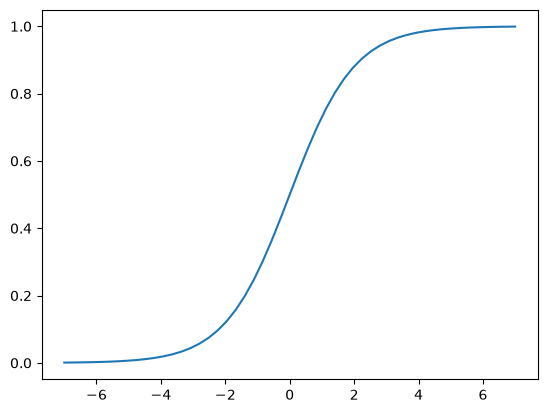

In [38]:
sigmoid(10000)        # 1.0
sigmoid(0)            # 0.5
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))       # S-shaped curve

So: **score > 0 ⇒ probability > 0.5; score < 0 ⇒ probability < 0.5.**

Both models are called **linear models** because the score inside is still a linear combination of the features.

### 9.3 In code

In [39]:
def linear_regression(xi):
    result = w0
    for j in range(len(w)):
        result = result + xi[j] * w[j]
    return result

def logistic_regression(xi):
    score = w0
    for j in range(len(w)):
        score = score + xi[j] * w[j]
    result = sigmoid(score)         # <- the only difference
    return result

### Remember

- **Logistic regression = linear regression + sigmoid.**
- Output: a probability in (0, 1); sigmoid(0) = 0.5.
- (Despite the name, it's used for classification.)

## Step 10: Training logistic regression with Scikit-Learn

**Goal:** train the model, get probabilities, turn them into decisions, and measure accuracy.

### 10.1 Train

In [40]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)

/Users/osoti/coosoti/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

- `solver` = the optimisation algorithm that finds the best weights (`lbfgs` is the default in modern versions).
- `fit(X, y)` = learn the weights. (Unlike linear regression in Module 2 there's no simple formula, so the weights are found iteratively.)

After training:

In [41]:
model.intercept_[0]     # the bias w0
model.coef_[0]          # 45 weights, one per column of X

array([ 4.74607733e-01, -1.74834448e-01, -4.07482874e-01, -2.97354207e-02,
       -7.79741682e-02,  6.26950259e-02, -8.90423111e-02, -8.13623037e-02,
       -3.43219821e-02, -7.33876068e-02, -3.35108915e-01,  3.16441637e-01,
       -8.90423111e-02,  3.68103071e-03, -2.58155965e-01,  1.41433611e-01,
        9.01276551e-03,  6.25406784e-02, -8.90423111e-02, -8.12079562e-02,
        2.65542982e-01, -8.90423111e-02, -2.84210260e-01, -2.31197222e-01,
        1.23487633e-01, -1.66046896e-01,  5.83373070e-02, -8.69908967e-02,
       -3.20494872e-02,  7.04623140e-02, -5.91315190e-02,  1.41433611e-01,
       -2.49143200e-01,  2.15427030e-01, -1.20310489e-01, -8.90423111e-02,
        1.01643211e-01, -7.08507937e-02, -8.90423111e-02,  5.21835159e-02,
        2.13345136e-01, -8.90423111e-02, -2.32012414e-01, -7.03699062e-02,
        3.81884127e-04])

> **Convergence warning?** With unscaled numerical features (like `totalcharges`, which reaches thousands) `lbfgs` may print a `ConvergenceWarning`. It means "I hit the iteration limit". For this lesson the results are still fine; raising `max_iter` or scaling features (`StandardScaler`) removes the warning.

### 10.2 Hard vs soft predictions

| Method | Returns |
|---|---|
| `model.predict(X)` | **hard** predictions: final 0/1 |
| `model.predict_proba(X)` | **soft** predictions: probabilities |

We want probabilities, so we can choose our own threshold:

In [42]:
y_pred = model.predict_proba(X_val)[:, 1]

`predict_proba` returns two columns: P(class 0) and P(class 1), which always add up to 1. `[:, 1]` means "all rows, column 1" = probability of churn.

### 10.3 Decision and accuracy

In [43]:
churn_decision = (y_pred >= 0.5)       # True/False array

**Accuracy** = fraction of correct predictions:

In [44]:
(y_val == churn_decision).mean()       # about 0.80

np.float64(0.8034066713981547)

Why `.mean()` works: comparing gives True/False, and the mean of True/False counts the share of True (True = 1, False = 0).

My run: **0.8034** validation accuracy (same as the lesson).

### Remember

- `fit`, `predict_proba(...)[:, 1]`, threshold, `(y == decision).mean()`.
- 0.5 is a default threshold, not a law; the next module explores better choices.

## Step 11: Interpreting the model

**Goal:** read what the model learned.

### 11.1 Match weights with names

`coef_` is just numbers. `zip` pairs two lists element by element:

In [45]:
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))      # {1: 'a', 2: 'b', 3: 'c', 4: 'd'}

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

In [46]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.475),
 'contract=one_year': np.float64(-0.175),
 'contract=two_year': np.float64(-0.407),
 'dependents=no': np.float64(-0.03),
 'dependents=yes': np.float64(-0.078),
 'deviceprotection=no': np.float64(0.063),
 'deviceprotection=no_internet_service': np.float64(-0.089),
 'deviceprotection=yes': np.float64(-0.081),
 'gender=female': np.float64(-0.034),
 'gender=male': np.float64(-0.073),
 'internetservice=dsl': np.float64(-0.335),
 'internetservice=fiber_optic': np.float64(0.316),
 'internetservice=no': np.float64(-0.089),
 'monthlycharges': np.float64(0.004),
 'multiplelines=no': np.float64(-0.258),
 'multiplelines=no_phone_service': np.float64(0.141),
 'multiplelines=yes': np.float64(0.009),
 'onlinebackup=no': np.float64(0.063),
 'onlinebackup=no_internet_service': np.float64(-0.089),
 'onlinebackup=yes': np.float64(-0.081),
 'onlinesecurity=no': np.float64(0.266),
 'onlinesecurity=no_internet_service': np.float64(-0.089),
 'onlinesecurity=yes'

Reading weights (same as in linear regression): **positive pushes churn probability up; negative pushes it down.** In the lesson: `contract=month-to-month` +0.475, `contract=two_year` −0.408, `internetservice=fiber_optic` +0.316. This matches the earlier EDA.

**How one-hot works inside the formula:** a customer has exactly one 1 among the contract columns and 0 in the others, so only **one** contract weight "counts" for that customer.

### 11.2 A smaller model: 3 features

A 45-weight model is hard to read, so train a small one on `contract`, `tenure`, `monthlycharges`:

In [47]:
small = ['contract', 'tenure', 'monthlycharges']
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

X_train_small = dv_small.transform(dicts_train_small)
model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Lesson's result:

| Feature | Weight |
|---|---:|
| bias (`w0`) | −2.477 |
| contract=month-to-month | +0.970 |
| contract=one_year | −0.025 |
| contract=two_year | −0.949 |
| monthlycharges | +0.027 per dollar |
| tenure | −0.036 per month |

### 11.3 Score a customer by hand

Customer: **two-year contract, $30/month, 24 months tenure**:

```
score = −2.47 + (−0.949) + 30·0.027 + 24·(−0.036)
      = −2.47 − 0.949 + 0.81 − 0.864
      = −3.473
```

In [48]:
sigmoid(-3.473)        # 0.030  -> 3% churn probability

np.float64(0.030090303318277657)

Only the two-year weight is used; the other two contract weights are multiplied by 0.

Another: **month-to-month, $50/month, 5 months**:

```
score = −2.47 + 0.97 + 50·0.027 − 5·0.036 = −0.33
sigmoid(−0.33) ≈ 0.42      -> 42% churn risk
```

> Rule of thumb: **score > 0 ⇒ more likely to churn than not.** (−0.33 is just under the middle.)

### Remember

- `dict(zip(names, weights))`.
- A one-hot category uses its weight only when it is 1.
- Weights are per-unit effects: tenure −0.036 means each extra month lowers the **score** by 0.036 (not the probability by 3.6%).

## Step 12: Using the model

**Goal:** the final steps: retrain on all training data, check on test, score single customers.

### 12.1 Final model on train + validation

Tuning is done, so we train on `df_full_train` (more data → slightly better model). The vectorizer is **refit** on this data too: **encoder and model always go together.**

In [49]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.churn.values

model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

/Users/osoti/coosoti/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### 12.2 One final check on test

In [50]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)

y_pred = model.predict_proba(X_test)[:, 1]
churn_decision = (y_pred >= 0.5)
(churn_decision == y_test).mean()

np.float64(0.8140525195173882)

Lesson: **0.8155**. My run: **0.8148**. Validation was 0.80. Close numbers mean the model generalizes; a big gap would signal overfitting.

### 12.3 Score one customer

In real life, a service receives **one customer as a dictionary**:

In [51]:
customer = dicts_test[-1]
X_one = dv.transform([customer])          # wrap in a list; transform, not fit_transform
model.predict_proba(X_one)[0, 1]

np.float64(0.6596407199515446)

The lesson gets 0.597; my run gets 0.655 (different library versions give slightly different weights). Either way it's above 0.5, and `y_test[-1]` is 1: the customer indeed churned.

Business use: probability above the threshold → send a promotional email.

The model is just numbers (weights + bias) plus the vectorizer's category list. To use it outside the notebook you'd save both to a file (covered in a later module).

## Step 13: The whole project in one place

In [52]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Load & clean
df = pd.read_csv('data-week-3.csv')
df.columns = df.columns.str.lower().str.replace(' ', '_')

text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce').fillna(0)
df.churn = (df.churn == 'yes').astype(int)

# 2. Split 60/20/20
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train, y_val, y_test = df_train.churn.values, df_val.churn.values, df_test.churn.values
del df_train['churn'], df_val['churn'], df_test['churn']

# 3. Feature lists
numerical = ['tenure', 'monthlycharges', 'totalcharges']
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice',
               'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup',
               'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies',
               'contract', 'paperlessbilling', 'paymentmethod']

# 4. Feature importance (on full train)
print(df_full_train.churn.mean())
print(df_full_train[numerical].corrwith(df_full_train.churn))
mi = df_full_train[categorical].apply(lambda s: mutual_info_score(s, df_full_train.churn))
print(mi.sort_values(ascending=False))

# 5. Encode + train + validate
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[categorical + numerical].to_dict(orient='records'))
X_val = dv.transform(df_val[categorical + numerical].to_dict(orient='records'))

model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)
print('val accuracy:', ((model.predict_proba(X_val)[:, 1] >= 0.5) == y_val).mean())

# 6. Final model on full train, check on test
dv = DictVectorizer(sparse=False)
X_full = dv.fit_transform(df_full_train[categorical + numerical].to_dict(orient='records'))
model = LogisticRegression(solver='lbfgs')
model.fit(X_full, df_full_train.churn.values)

X_test = dv.transform(df_test[categorical + numerical].to_dict(orient='records'))
print('test accuracy:', ((model.predict_proba(X_test)[:, 1] >= 0.5) == y_test).mean())

# 7. Score one customer
customer = df_test[categorical + numerical].to_dict(orient='records')[-1]
print(model.predict_proba(dv.transform([customer]))[0, 1])

0.26996805111821087
tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64
contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64
val accuracy: 0.8034066713981547
test accuracy: 0.8140525195173882
0.6596407199515446


/Users/osoti/coosoti/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/osoti/coosoti/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

**Numbers from my run vs. the lessons:**

| Quantity | Lesson | My run |
|---|---:|---:|
| Rows (train / val / test) | 4225 / 1409 / 1409 | same |
| Churn rate (full train) | 0.2700 | 0.2700 |
| Best MI (`contract`) | 0.0983 | 0.0983 |
| corr(tenure, churn) | −0.352 | −0.352 |
| Feature matrix shape | (4225, 45) | (4225, 45) |
| Validation accuracy | 0.8034 | 0.8034 |
| Test accuracy | 0.8155 | 0.8148 |

## Cheat sheets

### Formulas

| Name | Formula |
|---|---|
| Churn rate | `mean of the 0/1 target` |
| Difference | `group rate − global rate` |
| Risk ratio | `group rate / global rate` |
| Linear score | `w0 + Σ wj·xj` |
| Sigmoid | `1 / (1 + exp(−z))` |
| Logistic regression | `Sigmoid(w0 + Σ wj·xj)` |
| Accuracy | `(correct predictions) / (all predictions)` |

### Which importance measure?

| Feature type | Tool | Higher means |
|---|---|---|
| Categorical (per group) | risk ratio / difference | group differs more from average |
| Categorical (whole variable) | `mutual_info_score` | more informative |
| Numerical | `corrwith` | stronger relation (look at \|r\|) |

### Code reference

| Code | Meaning |
|---|---|
| `pd.to_numeric(s, errors='coerce')` | convert; unparseable → NaN |
| `(df.x == 'yes').astype(int)` | yes/no → 1/0 |
| `train_test_split(df, test_size=0.2, random_state=1)` | random split into two |
| `df.groupby('c').churn.agg(['mean','count'])` | churn rate per group |
| `mutual_info_score(a, b)` | mutual information |
| `df[nums].corrwith(df.y)` | correlation with target |
| `df[cols].to_dict(orient='records')` | rows → list of dicts |
| `DictVectorizer(sparse=False)` | one-hot encoder for dicts |
| `dv.fit_transform(...)` / `dv.transform(...)` | train / val & test |
| `dv.get_feature_names_out()` | column names |
| `LogisticRegression().fit(X, y)` | train |
| `.predict_proba(X)[:, 1]` | P(positive class) |
| `.intercept_[0]`, `.coef_[0]` | bias, weights |
| `dict(zip(names, weights))` | name each weight |

## Common confusions (FAQ)

**Q1. What is the difference between regression and classification?**
Regression predicts a number (a price). Classification predicts a category (churn: yes/no). Logistic regression, despite its name, is for classification.

**Q2. If the output is a probability, how do I get a yes/no?**
Choose a threshold (here 0.5): probability ≥ threshold → "yes".

**Q3. Why `predict_proba(...)[:, 1]`?**
It returns a 2-column table (P(0), P(1)). Column 1 is the probability of churn.

**Q4. `predict` vs `predict_proba`?**
`predict` gives the final 0/1 using a fixed 0.5 threshold; `predict_proba` gives probabilities so you can choose.

**Q5. Why is the sigmoid needed?**
A weighted sum can be −50 or +300; a probability can't. The sigmoid squashes any number into 0 to 1.

**Q6. What does a weight mean in logistic regression?**
Same as before: positive pushes the score (and probability) up, negative pushes it down. The effect is linear on the **score**, not directly on the probability.

**Q7. Why `test_size=0.25` the second time?**
Because the second split works on 80% of the data, and 25% of 80% = 20% of the original.

**Q8. Why use `fit` on train but only `transform` on validation/test?**
So the validation/test matrices use exactly the same columns as training. Refitting could change the columns.

**Q9. Why does the lesson use `df_full_train` for feature importance?**
More data gives steadier estimates; and we're not evaluating the model there, just exploring.

**Q10. Why is mutual information used for categorical and correlation for numerical?**
MI compares category groups; correlation measures a linear relationship between numbers.

**Q11. `seniorcitizen` is 0/1. Numerical or categorical?**
Categorical: it's a yes/no label, even though it looks like a number.

**Q12. Why is 80% accuracy "good"?**
27% churn means a model that always says "no churn" would already be right ~73% of the time. So 80% is a start, not a triumph. Later modules introduce better metrics for this reason.

**Q13. I get a ConvergenceWarning. Is something broken?**
No. The optimiser reached its iteration limit, usually because features have very different scales. Raise `max_iter` or scale features.

**Q14. The lesson code `df.dtypes == 'object'` gives me an empty list.**
You have pandas 3.x, where text columns are `str`. Use `not pd.api.types.is_numeric_dtype(df[c])` instead.

**Q15. My numbers differ slightly from the lesson.**
Different Scikit-Learn / pandas versions can change optimisation details slightly (see the table above). Small third-decimal differences are normal.

## Self-test questions

Try each question first, then click the arrow to reveal the answer.

1. **What do 1 and 0 mean in our target?**
<details><summary>Answer</summary>1 = churned (positive class), 0 = stayed.</details>

2. **How do you get the churn rate from a 0/1 column?**
<details><summary>Answer</summary>Take its mean.</details>

3. **Why `test_size=0.25` in the second split?**
<details><summary>Answer</summary>25% of the remaining 80% equals 20% of all data.</details>

4. **A group has churn rate 0.54, the global rate is 0.27. Risk ratio and meaning?**
<details><summary>Answer</summary>0.54 / 0.27 = 2.0: the group churns twice as often as average.</details>

5. **Which has more information about churn: a feature with MI 0.098 or 0.0001?**
<details><summary>Answer</summary>0.098.</details>

6. **What does a correlation of −0.35 between tenure and churn tell you?**
<details><summary>Answer</summary>Medium strength; longer tenure → less churn.</details>

7. **One-hot encode `[red, blue, red]`.**
<details><summary>Answer</summary>red = [1, 0, 1], blue = [0, 1, 0].</details>

8. **Why never `fit` the DictVectorizer on validation data?**
<details><summary>Answer</summary>It could change columns/order, so the matrix wouldn't match the trained model.</details>

9. **Write the logistic regression formula.**
<details><summary>Answer</summary>g(x) = Sigmoid(w0 + w1x1 + ... + wnxn), Sigmoid(z) = 1/(1+exp(−z)).</details>

10. **Compute sigmoid(0) and say what it means.**
<details><summary>Answer</summary>0.5: a coin flip; score 0 is the decision boundary.</details>

11. **Score = −3.47. More or less likely to churn than not?**
<details><summary>Answer</summary>Less likely (score < 0 ⇒ probability < 0.5; actually ≈ 3%).</details>

12. **What does `(y_val == churn_decision).mean()` compute?**
<details><summary>Answer</summary>Accuracy.</details>

13. **Why retrain on train + validation before the final test?**
<details><summary>Answer</summary>Hyperparameters/features are chosen, so more data helps; the test set stays untouched.</details>

14. **Why are most one-hot weights "unused" for any one customer?**
<details><summary>Answer</summary>Only the category column that is 1 contributes; the rest are multiplied by 0.</details>

# PART B: HOMEWORK 3 (Lead scoring) with working solutions

**Task:** predict whether a lead **converted** (signed up to the platform), using the 2026 lead-scoring dataset: 5,000 leads, target `converted`.

All answers below were computed by running the code in this document (pandas 3.0.2, scikit-learn 1.8.0). The homework states that the numeric options come from the pinned 2026 release and warns not to pick a "merely close" value, so use the number your own run produces and compare it to the options.

## Homework setup and data preparation

### Get the data

In [53]:
import pandas as pd
import numpy as np

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)        # or: !wget <url>, then pd.read_csv('course_lead_scoring_2026.csv')

df.shape        # (5000, 9)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Columns:

| Column | Type | Meaning |
|---|---|---|
| `lead_source` | categorical | where the lead came from |
| `industry` | categorical | the lead's industry |
| `employment_status` | categorical | employed, student, ... |
| `location` | categorical | region |
| `annual_income` | numerical | income |
| `number_of_courses_viewed` | numerical | courses the lead viewed |
| `interaction_count` | numerical | number of interactions |
| `lead_score` | numerical | a score for the lead |
| `converted` | **target** | 1 = signed up, 0 = didn't |

### Check missing values

In [54]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

```
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
```

Yes, there are missing values in several features. The homework rule:

- **categorical** features → fill with `'NA'`
- **numerical** features → fill with `0.0`

Define the feature lists **by listing them** (this avoids the pandas-3 `object` vs `str` problem entirely):

In [55]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

for c in categorical:
    df[c] = df[c].fillna('NA')

for c in numerical:
    df[c] = df[c].fillna(0.0)

df.isnull().sum().sum()      # 0  -> nothing missing now

np.int64(0)

> **Why the string `'NA'`?** It turns "missing" into its own category, so the one-hot encoder (which can't handle NaN) gets a normal string. Note: pandas can also read the literal text "NA" as missing when loading; here we're deliberately creating the category named `NA` ourselves.

> **Target balance (for context):** about 57.7% of the leads converted (mean of `converted` = 0.5766), a fairly balanced problem, unlike churn.

## Question 1

**What is the most frequent observation (mode) for the column `industry`?**
Options: `NA`, `technology`, `healthcare`, `retail`.

In [56]:
df.industry.mode()[0]
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

```
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
```

### ✅ Answer: **`technology`**

`.mode()` returns the most frequent value(s); `[0]` takes the first. `value_counts()` lets you see the whole ranking, and shows `NA` (the filled-in missing values) is only 240, nowhere near the top.

## Question 2

**Which two features have the biggest correlation?** (Consider only the four listed pairs.)

In [57]:
df[numerical].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


```
                          annual_income  number_of_courses_viewed  interaction_count  lead_score
annual_income                    1.0000                    0.1613             0.1228      0.2295
number_of_courses_viewed         0.1613                    1.0000             0.7216      0.7572
interaction_count                0.1228                    0.7216             1.0000      0.9157
lead_score                       0.2295                    0.7572             0.9157      1.0000
```

The four candidate pairs:

| Pair | Correlation |
|---|---:|
| `interaction_count` and `lead_score` | **0.9157** |
| `number_of_courses_viewed` and `lead_score` | 0.7572 |
| `number_of_courses_viewed` and `interaction_count` | 0.7216 |
| `annual_income` and `interaction_count` | 0.1228 |

### ✅ Answer: **`interaction_count` and `lead_score`**

How to read a correlation matrix: it's symmetric (the correlation of A with B equals B with A), and the diagonal is always 1 (every feature correlates perfectly with itself). Find the entry in the row/column of each pair and compare. Single pair, if you prefer:

In [58]:
df['interaction_count'].corr(df['lead_score'])      # 0.9157

np.float64(0.9157457980418671)

## Split the data

Use **exactly** these calls (same two-step 60/20/20 idea as the churn project, but with `random_state=42`):

In [59]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

len(df_train), len(df_val), len(df_test)       # (3000, 1000, 1000)

(3000, 1000, 1000)

Then reset the indexes, extract the target, and **delete it from the feature tables**:

In [60]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 3

**Which categorical variable has the biggest mutual information with `converted`?** Use the **training set only**; round the scores to 2 decimals with `round(score, 2)`.

In [61]:
from sklearn.metrics import mutual_info_score

for c in categorical:
    score = mutual_info_score(df_train[c], y_train)
    print(c, round(score, 2), '   (raw:', score, ')')

lead_source 0.03    (raw: 0.03434605791617973 )
industry 0.0    (raw: 0.0019945636715935217 )
employment_status 0.02    (raw: 0.018965604906982875 )
location 0.0    (raw: 0.001042763579701525 )


```
lead_source        0.03   (raw: 0.03434605791617973)
industry           0.0    (raw: 0.0019945636715935217)
employment_status  0.02   (raw: 0.018965604906982875)
location           0.0    (raw: 0.001042763579701525)
```

### ✅ Answer: **`lead_source`**

Remember MI measures how much knowing the variable tells you about conversion. `lead_source` (0.034) is clearly the most informative; `industry` and `location` are close to 0, so they carry almost no information about conversion.

> Why training set only? Choosing/judging features on validation or test data would leak information from those sets into your decisions.

## Question 4

**Train a logistic regression with one-hot encoding on the training set and compute accuracy on validation (2 decimals).**

In [62]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

features = categorical + numerical

train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)      # fit on TRAIN only
X_val = dv.transform(val_dicts)              # transform only

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)                # hard predictions (default 0.5 threshold)
accuracy = (y_pred == y_val).mean()
accuracy                                     # 0.645

np.float64(0.645)

The feature matrix has shape (3000, 28).

Options: 0.55, 0.65, 0.75, 0.85.

### ✅ Answer: **0.65**

The exact accuracy is **0.645** (645 of 1000 validation leads correct), which rounds to 0.65, the matching option.

> ⚠️ **A rounding trap.** `round(accuracy, 2)` can print **0.64** if `accuracy` is a NumPy float (NumPy rounds exact halves to the nearest *even* digit, so 64.5 → 64). Ordinary rounding (half up) gives 0.65, which is the intended answer. Check this yourself:
> ```python
> round(np.float64(0.645), 2)   # 0.64  (NumPy: round half to even)
> round(float(0.645), 2)        # 0.65
> f"{0.645:.2f}"                # '0.65'
> ```
> Since the options are 0.55 / 0.65 / 0.75 / 0.85, the unambiguous match is **0.65**.

**Why `liblinear`, `C=1.0`, `max_iter=1000`, `random_state=42`?** The homework pins these so results are reproducible across scikit-learn versions. (`C` is the regularization strength; see Question 6.)

## Question 5

**Feature elimination: which feature has the smallest accuracy difference when removed?**
Options: `lead_source`, `number_of_courses_viewed`, `interaction_count`.

**Idea:** a feature that matters will hurt accuracy a lot when removed; one that doesn't matter changes accuracy little. For each feature:

1. Train the model **without** that feature.
2. Compute validation accuracy.
3. `difference = original accuracy − accuracy without the feature`.

In [63]:
def train_and_score(feature_list):
    cats = [f for f in feature_list if f in categorical]
    nums = [f for f in feature_list if f in numerical]

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_train[cats + nums].to_dict(orient='records'))
    X_v = dv.transform(df_val[cats + nums].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_tr, y_train)

    return (model.predict(X_v) == y_val).mean()


all_features = categorical + numerical
original = train_and_score(all_features)          # 0.645 (do NOT round)

for f in all_features:
    without = [x for x in all_features if x != f]
    acc = train_and_score(without)
    print(f"{f:26s} acc without = {acc:.3f}   difference = {original - acc:+.3f}")

lead_source                acc without = 0.642   difference = +0.003
industry                   acc without = 0.645   difference = +0.000
employment_status          acc without = 0.645   difference = +0.000
location                   acc without = 0.645   difference = +0.000
annual_income              acc without = 0.724   difference = -0.079
number_of_courses_viewed   acc without = 0.643   difference = +0.002
interaction_count          acc without = 0.601   difference = +0.044
lead_score                 acc without = 0.644   difference = +0.001


```
lead_source                acc without = 0.642   difference = +0.003
industry                   acc without = 0.645   difference = +0.000
employment_status          acc without = 0.645   difference = +0.000
location                   acc without = 0.645   difference = +0.000
annual_income              acc without = 0.724   difference = -0.079
number_of_courses_viewed   acc without = 0.643   difference = +0.002
interaction_count          acc without = 0.601   difference = +0.044
lead_score                 acc without = 0.644   difference = +0.001
```

Only the three listed options count:

| Feature | Difference |
|---|---:|
| `lead_source` | +0.003 |
| `number_of_courses_viewed` | **+0.002** |
| `interaction_count` | +0.044 |

### ✅ Answer: **`number_of_courses_viewed`**

It has the smallest difference (0.002) among the options: removing it barely changes accuracy, so it's the least useful of the three. `interaction_count` is clearly the most useful (removing it costs 4.4 points of accuracy).

> **"The difference doesn't have to be positive."** Look at `annual_income`: removing it *raises* accuracy from 0.645 to 0.724 (difference −0.079), meaning that with this model and settings, annual income actually *hurts* validation accuracy. It isn't one of the options, but it's a fascinating warning: a feature can be informative for the target yet still confuse a model (for instance, because its values are large and unscaled, or because of the missing values we filled with 0). Scaling numerical features (`StandardScaler`) is a good follow-up experiment.

## Question 6

**Regularized logistic regression: which `C` gives the best validation accuracy?**
Try `C` in `[0.000001, 0.00001, 0.0001, 0.001]`, with all features as in Q4; round accuracy to **3** decimals; if there are ties, choose the **smallest** `C`.

**What is `C`?** In scikit-learn, `C` is the **inverse** of regularization strength: **small `C` = strong regularization** (weights squeezed toward zero), large `C` = weak regularization. (Compare with `r` from Module 2, where a *larger* `r` meant *more* regularization. `C` works the opposite way.)

In [64]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    acc = (model.predict(X_val) == y_val).mean()
    print(C, round(float(acc), 3))

1e-06 0.598
1e-05 0.598
0.0001 0.613
0.001 0.645


```
1e-06   0.598
1e-05   0.598
0.0001  0.613
0.001   0.645
```

### ✅ Answer: **0.001**

It gives the best validation accuracy (0.645). No tie at the top, so the "smallest C" rule isn't needed. With very small `C` the model is squeezed so hard that it basically predicts the majority class (conversion rate is about 0.6 in validation, which is exactly why 0.598 appears: that's roughly "always predict converted").

## Complete homework solution script

This single cell re-runs everything from scratch and reproduces every answer above.

In [65]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# ---------- Data ----------
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

print(df.isnull().sum())                       # there are missing values

for c in categorical:
    df[c] = df[c].fillna('NA')
for c in numerical:
    df[c] = df[c].fillna(0.0)

# ---------- Q1 ----------
print('Q1:', df.industry.mode()[0])            # technology

# ---------- Q2 ----------
print(df[numerical].corr().round(4))
pairs = [('interaction_count', 'lead_score'),
         ('number_of_courses_viewed', 'lead_score'),
         ('number_of_courses_viewed', 'interaction_count'),
         ('annual_income', 'interaction_count')]
for a, b in pairs:
    print('Q2:', a, b, round(df[a].corr(df[b]), 4))
# biggest: interaction_count & lead_score

# ---------- Split ----------
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

# ---------- Q3 ----------
for c in categorical:
    print('Q3:', c, round(float(mutual_info_score(df_train[c], y_train)), 2))
# biggest: lead_source

# ---------- helpers ----------
def train_and_score(feature_list, C=1.0):
    cats = [f for f in feature_list if f in categorical]
    nums = [f for f in feature_list if f in numerical]

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_train[cats + nums].to_dict(orient='records'))
    X_v = dv.transform(df_val[cats + nums].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_tr, y_train)

    return float((model.predict(X_v) == y_val).mean())

features = categorical + numerical

# ---------- Q4 ----------
acc = train_and_score(features)
print('Q4:', acc, '->', f'{acc:.2f}')            # 0.645 -> 0.65

# ---------- Q5 ----------
for f in features:
    without = [x for x in features if x != f]
    print('Q5:', f, round(acc - train_and_score(without), 4))
# among the options, smallest: number_of_courses_viewed

# ---------- Q6 ----------
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    print('Q6:', C, round(train_and_score(features, C=C), 3))
# best: 0.001

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
Q1: technology
                          annual_income  number_of_courses_viewed  \
annual_income                    1.0000                    0.1613   
number_of_courses_viewed         0.1613                    1.0000   
interaction_count                0.1228                    0.7216   
lead_score                       0.2295                    0.7572   

                          interaction_count  lead_score  
annual_income                        0.1228      0.2295  
number_of_courses_viewed             0.7216      0.7572  
interaction_count                    1.0000      0.9157  
lead_score                           0.9157      1.0000  
Q2: interaction_count lead_score 0.9157
Q2: numb

## Answer summary

| Question | Answer | Key evidence |
|---|---|---|
| **Q1** | **`technology`** | 1,173 rows: the most frequent industry |
| **Q2** | **`interaction_count` and `lead_score`** | r = 0.9157, the highest of the four pairs |
| **Q3** | **`lead_source`** | MI = 0.03 (others: 0.00 to 0.02) |
| **Q4** | **0.65** | accuracy = 0.645 on validation |
| **Q5** | **`number_of_courses_viewed`** | difference = 0.002 (vs. 0.003 and 0.044) |
| **Q6** | **0.001** | accuracy = 0.645 (others 0.598 / 0.598 / 0.613) |

### Caveats worth knowing

- **Versions:** answers were computed with pandas 3.0.2 and scikit-learn 1.8.0 on the pinned 2026 dataset. The homework pins the solver and parameters so answers don't depend on the library version; your values should match. Always check your own run against the options.
- **Q4 rounding:** exact accuracy is 0.645; use half-up rounding (0.65) as shown above.
- **Q5 depends on the model and split:** the differences are tiny (0.002 vs 0.003 are single-digit counts of leads out of 1,000), so use the exact split calls given and don't round before subtracting.
- **Submit** at https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw03

### Optional extensions (not graded)

1. Scale the numerical features with `StandardScaler` and redo Q4 and Q5. Does `annual_income` still hurt accuracy?
2. Try different probability thresholds than 0.5 using `predict_proba`.
3. Compare to the churn project: the lead data is nearly balanced (58% positive) while churn is imbalanced (27%). How would accuracy mislead differently in each?